# Sri Lanka Bird Habitat-Guild Classification — v6: 6-Class Target (Coastal Pair Merged)

**Why this notebook exists:** after v5 (`04_ensemble_tuning_and_explainability.ipynb`) landed at macro-F1 0.729 / accuracy 71.4% on the 7-class habitat-guild target, the question came up of whether accuracy could be pushed past 90%. Before touching a single hyperparameter, it's worth asking whether that's even *possible* on this data.

**The duplicate-feature-row ceiling.** Multiple species/guilds get recorded at the same rounded location with the same climate snapshot — environmentally identical rows with different true labels. No classifier, however good, can resolve those; the best any model can do is guess the majority label within each such group. That sets a hard mathematical ceiling on achievable accuracy, computed below directly from the data (not assumed).


## 1. The accuracy ceiling, computed directly

In [1]:
import sys, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd().parent if not (Path.cwd() / "src").exists() else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

df7 = pd.read_csv(PROJECT_ROOT / "data" / "processed" / "bird_habitat_guild_classification.csv")

numeric_cols = [
    "decimalLatitude", "decimalLongitude", "avg_rad", "NDVI", "elevation_meters",
    "Carbon_Mass", "Dust_Mass", "SO2_Mass", "Sulfate_Mass", "Sea_Salt_Mass",
    "Total_Aerosol_Extinction", "temp_mean", "rainfall", "wind_mean",
    "humid_mean", "shortwave_radiation", "lka_general_2020",
]
categorical_cols = ["stateProvince", "LandCover_Class"]
feat_cols = numeric_cols + categorical_cols

def accuracy_ceiling(frame, label_col):
    dup_mask = frame.duplicated(subset=feat_cols, keep=False)
    n_total = len(frame)
    n_nondup = (~dup_mask).sum()
    majority = lambda g: g.value_counts(normalize=True).max()
    grouped = frame[dup_mask].groupby(feat_cols)
    best_correct = n_nondup + (grouped[label_col].apply(majority) * grouped.size()).sum()
    return best_correct / n_total * 100, dup_mask.mean() * 100

ceiling_7, duprate_7 = accuracy_ceiling(df7, "habitat_guild")
print(f"7-class target:  {duprate_7:.1f}% of rows are feature-duplicates of a different-labelled row  ->  accuracy ceiling = {ceiling_7:.1f}%")
print("(i.e. 90% accuracy is mathematically unreachable on the 7-class target with these features -- confirmed, not assumed)")


7-class target:  63.9% of rows are feature-duplicates of a different-labelled row  ->  accuracy ceiling = 86.9%
(i.e. 90% accuracy is mathematically unreachable on the 7-class target with these features -- confirmed, not assumed)


## 2. Why 6 classes — merging the one pair v3/v4's own analysis flagged as closest remaining

v3's centroid-distance analysis (the same one that justified merging 5 species into 2 guilds for v4) already showed *Thalasseus bergii* and *Numenius arquata* — both low-elevation coastal species — sitting closer to each other (~1.7 standardized distance) than to any of the 4 other still-distinct guilds, even though they were kept separate in v4 because that distance was still clearly larger than the within-cluster distances that justified the original 5-species merge (0.8-1.5). Merging this pair now is the next smallest, most defensible class-count reduction — not an arbitrary choice to chase a number.


In [2]:
MERGE_MAP = {
    "Thalasseus bergii (marine coastal)": "Coastal (tern + curlew)",
    "Numenius arquata (coastal wader)": "Coastal (tern + curlew)",
}
df7["habitat_guild_6"] = df7["habitat_guild"].replace(MERGE_MAP)

ceiling_6, duprate_6 = accuracy_ceiling(df7, "habitat_guild_6")
print(f"6-class target:  accuracy ceiling = {ceiling_6:.1f}%  (vs {ceiling_7:.1f}% for 7 classes)")
print()
print(df7["habitat_guild_6"].value_counts())

DATA_PATH_6 = PROJECT_ROOT / "data" / "processed" / "bird_habitat_guild_6class_classification.csv"
df7.to_csv(DATA_PATH_6, index=False)
print("\nSaved:", DATA_PATH_6)


6-class target:  accuracy ceiling = 88.1%  (vs 86.9% for 7 classes)

habitat_guild_6
Lowland open-country/wetland-edge      3586
Upland scrub/woodland-edge             2446
Coastal (tern + curlew)                2312
Harpactes fasciatus (rainforest)       1751
Hirundo domicola (highland)            1275
Motacilla alba (urban/wetland-edge)     640
Name: count, dtype: int64



Saved: D:\Msc\Sem_2\Applied ML\Sri Lanka Rare birds\data\processed\bird_habitat_guild_6class_classification.csv


**Honest framing going in:** even 6 classes only raises the ceiling to ~88%, still short of 90% — reaching 90% outright would require collapsing to a near-binary split (upland/forest vs. lowland/coastal, ceiling 95.9%), which guts the "classify habitat guild" problem into "is elevation high or low." This notebook runs the full tuned-model + ensemble + SHAP/LIME pipeline from v5 on the 6-class target to see how close models actually get to the *achievable* 88% ceiling, and reports the real number rather than a target picked in advance.


## 3. Setup and data

In [3]:
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, RandomizedSearchCV, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    BaggingClassifier, AdaBoostClassifier, GradientBoostingClassifier,
    RandomForestClassifier, HistGradientBoostingClassifier,
    VotingClassifier, StackingClassifier,
)
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, ConfusionMatrixDisplay,
)
from xgboost import XGBClassifier
import shap
import lime
import lime.lime_tabular

df = pd.read_csv(DATA_PATH_6, parse_dates=["eventDate"])
X = pd.get_dummies(df[numeric_cols + categorical_cols], columns=categorical_cols, drop_first=True)
y = df["habitat_guild_6"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
sw_train = compute_sample_weight(class_weight="balanced", y=y_train)

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

print(f"Train: {len(X_train)} rows   Test: {len(X_test)} rows   Features: {X_train.shape[1]}")
print("Classes:", sorted(y.unique()))


Train: 9608 rows   Test: 2402 rows   Features: 51
Classes: ['Coastal (tern + curlew)', 'Harpactes fasciatus (rainforest)', 'Hirundo domicola (highland)', 'Lowland open-country/wetland-edge', 'Motacilla alba (urban/wetland-edge)', 'Upland scrub/woodland-edge']


In [4]:
results = {}

def report(name, model, X_te, store=True):
    preds = model.predict(X_te)
    acc = accuracy_score(y_test, preds)
    bal = balanced_accuracy_score(y_test, preds)
    f1m = f1_score(y_test, preds, average="macro")
    if store:
        results[name] = {"accuracy": acc, "balanced_accuracy": bal, "f1_macro": f1m}
    print(f"{name}: accuracy={acc:.4f}  balanced_accuracy={bal:.4f}  macro-F1={f1m:.4f}")
    print(classification_report(y_test, preds))
    fig, ax = plt.subplots(figsize=(7, 6))
    ConfusionMatrixDisplay.from_predictions(y_test, preds, ax=ax, xticks_rotation=90, colorbar=False)
    ax.set_title(f"{name} — confusion matrix")
    plt.tight_layout()
    plt.show()
    return preds


## 4. Tuned individual models (same search spaces as v5, re-run on the 6-class target)

Logistic Regression best params: {'C': 100}
Logistic Regression (tuned): accuracy=0.6682  balanced_accuracy=0.7439  macro-F1=0.7028
                                     precision    recall  f1-score   support

            Coastal (tern + curlew)       0.58      0.64      0.61       463
   Harpactes fasciatus (rainforest)       0.85      0.92      0.88       350
        Hirundo domicola (highland)       0.74      0.90      0.81       255
  Lowland open-country/wetland-edge       0.61      0.51      0.56       717
Motacilla alba (urban/wetland-edge)       0.63      0.94      0.76       128
         Upland scrub/woodland-edge       0.66      0.56      0.61       489

                           accuracy                           0.67      2402
                          macro avg       0.68      0.74      0.70      2402
                       weighted avg       0.66      0.67      0.66      2402



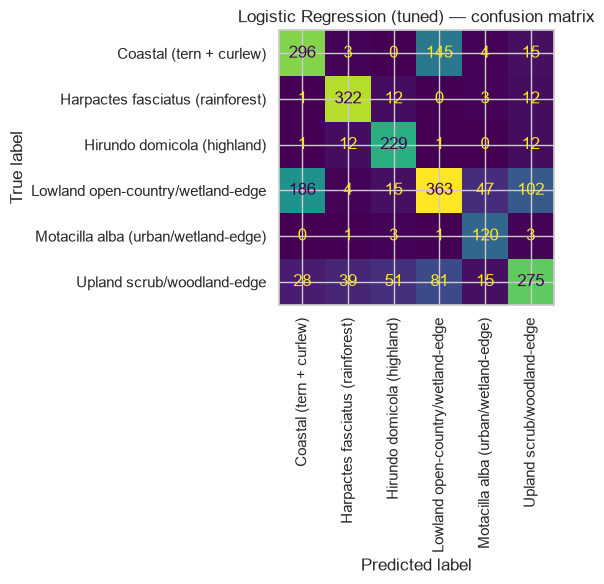

In [5]:
param_grid = {"C": [0.01, 0.1, 1, 10, 100]}
logreg_search = GridSearchCV(
    LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
    param_grid, cv=3, scoring="f1_macro", n_jobs=-1,
)
logreg_search.fit(X_train_scaled, y_train)
print("Logistic Regression best params:", logreg_search.best_params_)
_ = report("Logistic Regression (tuned)", logreg_search.best_estimator_, X_test_scaled)


SVM best params: {'C': 10, 'gamma': 'scale'}


SVM (RBF, tuned): accuracy=0.7161  balanced_accuracy=0.7782  macro-F1=0.7479
                                     precision    recall  f1-score   support

            Coastal (tern + curlew)       0.65      0.68      0.67       463
   Harpactes fasciatus (rainforest)       0.85      0.95      0.90       350
        Hirundo domicola (highland)       0.76      0.92      0.83       255
  Lowland open-country/wetland-edge       0.66      0.60      0.63       717
Motacilla alba (urban/wetland-edge)       0.73      0.93      0.82       128
         Upland scrub/woodland-edge       0.71      0.58      0.64       489

                           accuracy                           0.72      2402
                          macro avg       0.73      0.78      0.75      2402
                       weighted avg       0.71      0.72      0.71      2402



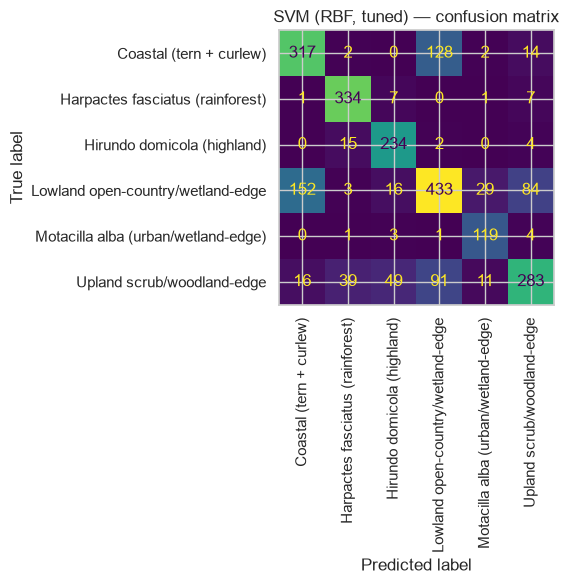

In [6]:
param_grid = {"C": [1, 10, 100], "gamma": ["scale", 0.01, 0.1]}
svm_search = GridSearchCV(
    SVC(kernel="rbf", class_weight="balanced", probability=False, random_state=RANDOM_STATE),
    param_grid, cv=3, scoring="f1_macro", n_jobs=-1,
)
svm_search.fit(X_train_scaled, y_train)
print("SVM best params:", svm_search.best_params_)
_ = report("SVM (RBF, tuned)", svm_search.best_estimator_, X_test_scaled)


Bagging best params: {'n_estimators': 200, 'max_samples': 1.0, 'max_features': 0.5, 'estimator__max_depth': 15}


Bagging: accuracy=0.7465  balanced_accuracy=0.7913  macro-F1=0.7764
                                     precision    recall  f1-score   support

            Coastal (tern + curlew)       0.71      0.67      0.69       463
   Harpactes fasciatus (rainforest)       0.90      0.95      0.93       350
        Hirundo domicola (highland)       0.82      0.86      0.84       255
  Lowland open-country/wetland-edge       0.67      0.68      0.67       717
Motacilla alba (urban/wetland-edge)       0.76      0.92      0.83       128
         Upland scrub/woodland-edge       0.73      0.67      0.70       489

                           accuracy                           0.75      2402
                          macro avg       0.77      0.79      0.78      2402
                       weighted avg       0.74      0.75      0.74      2402



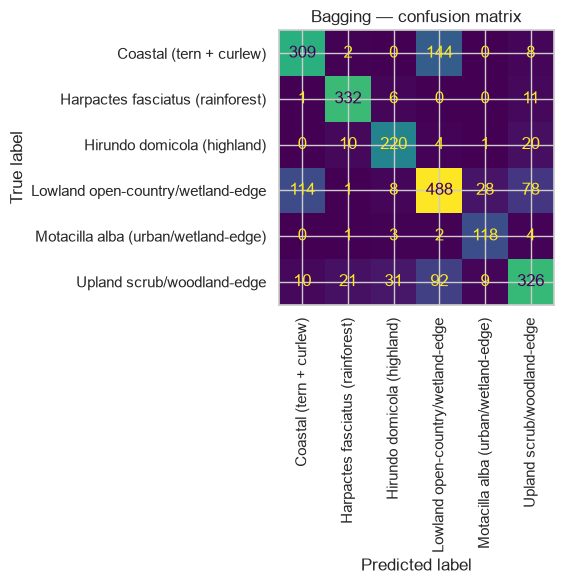

In [7]:
param_dist = {
    "n_estimators": [50, 100, 200, 300],
    "max_samples": [0.5, 0.7, 1.0],
    "max_features": [0.5, 0.7, 1.0],
    "estimator__max_depth": [5, 10, 15, None],
}
base_tree = DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE)
bagging_search = RandomizedSearchCV(
    BaggingClassifier(estimator=base_tree, random_state=RANDOM_STATE, n_jobs=-1),
    param_dist, n_iter=15, cv=3, scoring="f1_macro", random_state=RANDOM_STATE, n_jobs=-1,
)
bagging_search.fit(X_train, y_train)
print("Bagging best params:", bagging_search.best_params_)
bagging_best = bagging_search.best_estimator_
_ = report("Bagging", bagging_best, X_test)


AdaBoost best params: {'n_estimators': 50, 'learning_rate': 0.1, 'estimator__max_depth': 3}
AdaBoost: accuracy=0.6607  balanced_accuracy=0.7428  macro-F1=0.6964
                                     precision    recall  f1-score   support

            Coastal (tern + curlew)       0.57      0.72      0.64       463
   Harpactes fasciatus (rainforest)       0.82      0.93      0.87       350
        Hirundo domicola (highland)       0.73      0.92      0.81       255
  Lowland open-country/wetland-edge       0.61      0.46      0.53       717
Motacilla alba (urban/wetland-edge)       0.66      0.93      0.77       128
         Upland scrub/woodland-edge       0.64      0.50      0.56       489

                           accuracy                           0.66      2402
                          macro avg       0.67      0.74      0.70      2402
                       weighted avg       0.66      0.66      0.65      2402



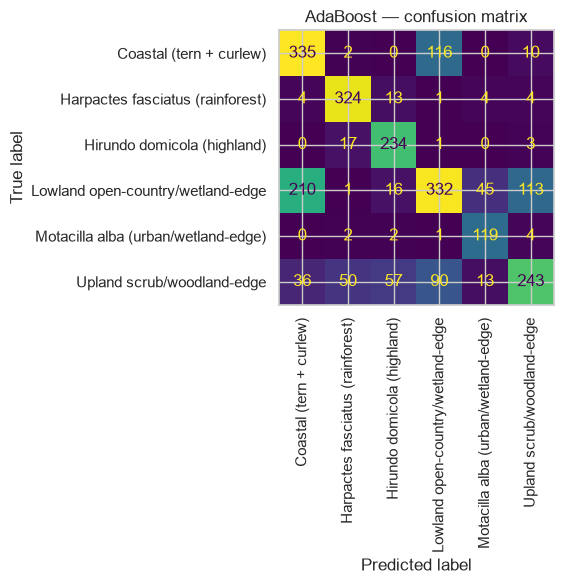

In [8]:
param_dist = {
    "n_estimators": [50, 100, 200, 300],
    "learning_rate": [0.01, 0.05, 0.1, 0.5, 1.0],
    "estimator__max_depth": [1, 2, 3],
}
base_tree = DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE)
ada_search = RandomizedSearchCV(
    AdaBoostClassifier(estimator=base_tree, random_state=RANDOM_STATE),
    param_dist, n_iter=15, cv=3, scoring="f1_macro", random_state=RANDOM_STATE, n_jobs=-1,
)
ada_search.fit(X_train, y_train, sample_weight=sw_train)
print("AdaBoost best params:", ada_search.best_params_)
ada_best = ada_search.best_estimator_
_ = report("AdaBoost", ada_best, X_test)


Gradient Boosting best params: {'subsample': 0.7, 'n_estimators': 200, 'max_depth': 5, 'learning_rate': 0.05}
Gradient Boosting: accuracy=0.7435  balanced_accuracy=0.7989  macro-F1=0.7750
                                     precision    recall  f1-score   support

            Coastal (tern + curlew)       0.68      0.70      0.69       463
   Harpactes fasciatus (rainforest)       0.91      0.95      0.93       350
        Hirundo domicola (highland)       0.81      0.90      0.85       255
  Lowland open-country/wetland-edge       0.69      0.62      0.65       717
Motacilla alba (urban/wetland-edge)       0.74      0.94      0.83       128
         Upland scrub/woodland-edge       0.72      0.68      0.70       489

                           accuracy                           0.74      2402
                          macro avg       0.76      0.80      0.78      2402
                       weighted avg       0.74      0.74      0.74      2402



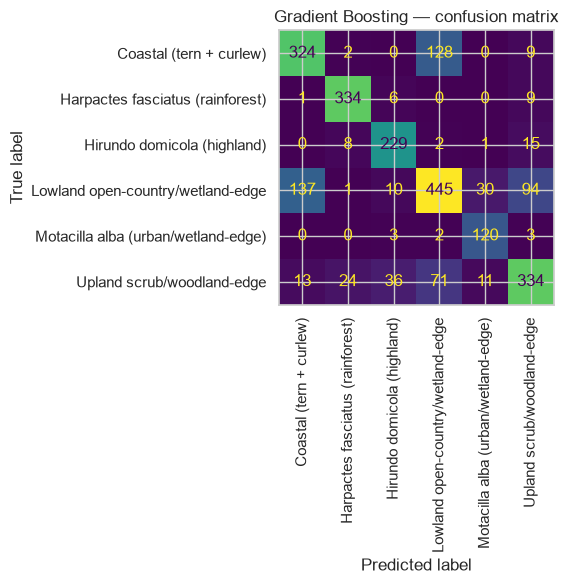

In [9]:
param_dist = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "max_depth": [2, 3, 4, 5],
    "subsample": [0.7, 0.85, 1.0],
}
gb_search = RandomizedSearchCV(
    GradientBoostingClassifier(random_state=RANDOM_STATE),
    param_dist, n_iter=15, cv=3, scoring="f1_macro", random_state=RANDOM_STATE, n_jobs=-1,
)
gb_search.fit(X_train, y_train, sample_weight=sw_train)
print("Gradient Boosting best params:", gb_search.best_params_)
gb_best = gb_search.best_estimator_
_ = report("Gradient Boosting", gb_best, X_test)


`XGBStringLabelWrapper` — same wrapper as v5: label-encodes internally so `fit`/`predict`/`predict_proba` take/return the same string guild names as every other classifier here, with named `__init__` params (not `**kwargs`) so `clone()`/`get_params()` work inside `VotingClassifier`/`StackingClassifier`, and `ClassifierMixin` listed before `BaseEstimator` so `is_classifier()` recognizes it.

In [10]:
class XGBStringLabelWrapper(ClassifierMixin, BaseEstimator):
    def __init__(self, n_estimators=300, max_depth=4, learning_rate=0.05,
                 subsample=0.7, colsample_bytree=0.85, objective="multi:softprob",
                 eval_metric="mlogloss", random_state=42, n_jobs=-1):
        self.n_estimators = n_estimators
        self.max_depth = max_depth
        self.learning_rate = learning_rate
        self.subsample = subsample
        self.colsample_bytree = colsample_bytree
        self.objective = objective
        self.eval_metric = eval_metric
        self.random_state = random_state
        self.n_jobs = n_jobs

    def fit(self, X, y, sample_weight=None):
        self.le_ = LabelEncoder().fit(y)
        self.classes_ = self.le_.classes_
        y_enc = self.le_.transform(y)
        if sample_weight is None:
            sample_weight = compute_sample_weight(class_weight="balanced", y=y)
        self.model_ = XGBClassifier(
            n_estimators=self.n_estimators, max_depth=self.max_depth,
            learning_rate=self.learning_rate, subsample=self.subsample,
            colsample_bytree=self.colsample_bytree, objective=self.objective,
            eval_metric=self.eval_metric, random_state=self.random_state, n_jobs=self.n_jobs,
        )
        self.model_.fit(X, y_enc, sample_weight=sample_weight)
        return self

    def predict(self, X):
        return self.le_.inverse_transform(self.model_.predict(X))

    def predict_proba(self, X):
        return self.model_.predict_proba(X)


XGBoost best params: {'subsample': 0.85, 'n_estimators': 300, 'max_depth': 6, 'learning_rate': 0.05, 'colsample_bytree': 0.7}
XGBoost: accuracy=0.7415  balanced_accuracy=0.7981  macro-F1=0.7756
                                     precision    recall  f1-score   support

            Coastal (tern + curlew)       0.68      0.68      0.68       463
   Harpactes fasciatus (rainforest)       0.92      0.95      0.93       350
        Hirundo domicola (highland)       0.82      0.90      0.86       255
  Lowland open-country/wetland-edge       0.67      0.63      0.65       717
Motacilla alba (urban/wetland-edge)       0.74      0.95      0.83       128
         Upland scrub/woodland-edge       0.73      0.68      0.70       489

                           accuracy                           0.74      2402
                          macro avg       0.76      0.80      0.78      2402
                       weighted avg       0.74      0.74      0.74      2402



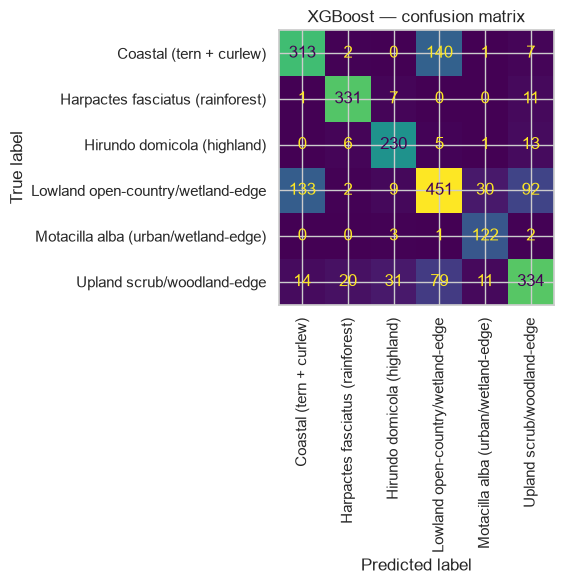

In [11]:
param_dist = {
    "n_estimators": [100, 200, 300],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "max_depth": [3, 4, 5, 6],
    "subsample": [0.7, 0.85, 1.0],
    "colsample_bytree": [0.7, 0.85, 1.0],
}
xgb_search = RandomizedSearchCV(
    XGBStringLabelWrapper(random_state=RANDOM_STATE),
    param_dist, n_iter=15, cv=3, scoring="f1_macro", random_state=RANDOM_STATE, n_jobs=-1,
)
xgb_search.fit(X_train, y_train)
print("XGBoost best params:", xgb_search.best_params_)
xgb_best = xgb_search.best_estimator_
_ = report("XGBoost", xgb_best, X_test)


Random Forest best params: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 15}
Random Forest: accuracy=0.7473  balanced_accuracy=0.7998  macro-F1=0.7781


                                     precision    recall  f1-score   support

            Coastal (tern + curlew)       0.69      0.68      0.68       463
   Harpactes fasciatus (rainforest)       0.91      0.95      0.93       350
        Hirundo domicola (highland)       0.82      0.92      0.86       255
  Lowland open-country/wetland-edge       0.68      0.65      0.66       717
Motacilla alba (urban/wetland-edge)       0.74      0.93      0.82       128
         Upland scrub/woodland-edge       0.73      0.68      0.71       489

                           accuracy                           0.75      2402
                          macro avg       0.76      0.80      0.78      2402
                       weighted avg       0.74      0.75      0.74      2402



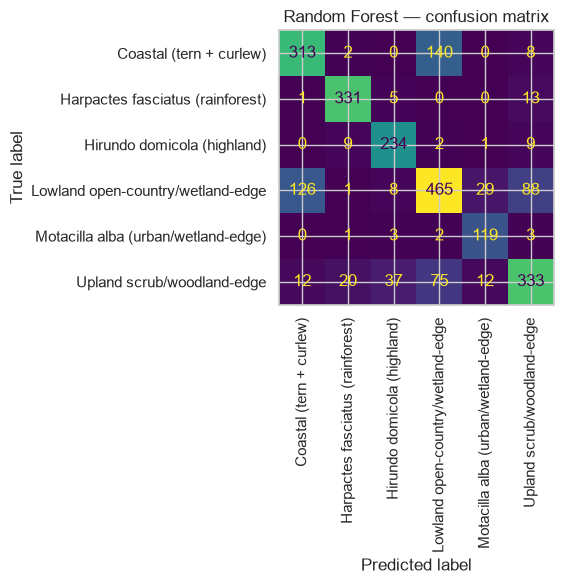

In [12]:
param_dist = {
    "n_estimators": [200, 300, 400],
    "max_depth": [10, 15, 20, None],
    "min_samples_leaf": [1, 5, 10],
    "max_features": ["sqrt", "log2", 0.5],
}
rf_search = RandomizedSearchCV(
    RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
    param_dist, n_iter=15, cv=3, scoring="f1_macro", random_state=RANDOM_STATE, n_jobs=-1,
)
rf_search.fit(X_train, y_train)
print("Random Forest best params:", rf_search.best_params_)
rf_best = rf_search.best_estimator_
_ = report("Random Forest", rf_best, X_test)


HistGradientBoosting best params: {'max_leaf_nodes': 31, 'max_iter': 100, 'max_depth': 5, 'learning_rate': 0.1}
HistGradientBoosting: accuracy=0.7377  balanced_accuracy=0.7950  macro-F1=0.7707
                                     precision    recall  f1-score   support

            Coastal (tern + curlew)       0.68      0.68      0.68       463
   Harpactes fasciatus (rainforest)       0.91      0.95      0.93       350
        Hirundo domicola (highland)       0.81      0.91      0.86       255
  Lowland open-country/wetland-edge       0.67      0.63      0.65       717
Motacilla alba (urban/wetland-edge)       0.73      0.95      0.82       128
         Upland scrub/woodland-edge       0.72      0.65      0.68       489

                           accuracy                           0.74      2402
                          macro avg       0.75      0.79      0.77      2402
                       weighted avg       0.73      0.74      0.73      2402



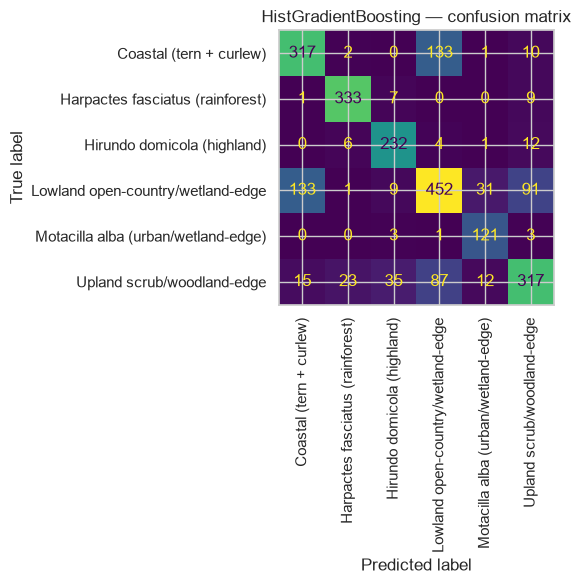

In [13]:
param_dist = {
    "max_iter": [100, 200, 300],
    "learning_rate": [0.01, 0.05, 0.1, 0.2],
    "max_depth": [3, 5, 8, None],
    "max_leaf_nodes": [15, 31, 63],
}
hgb_search = RandomizedSearchCV(
    HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE),
    param_dist, n_iter=15, cv=3, scoring="f1_macro", random_state=RANDOM_STATE, n_jobs=-1,
)
hgb_search.fit(X_train, y_train)
print("HistGradientBoosting best params:", hgb_search.best_params_)
hgb_best = hgb_search.best_estimator_
_ = report("HistGradientBoosting", hgb_best, X_test)


## 5. Individual models, compared

                             accuracy  balanced_accuracy  f1_macro
Random Forest                  0.7473             0.7998    0.7781
Bagging                        0.7465             0.7913    0.7764
XGBoost                        0.7415             0.7981    0.7756
Gradient Boosting              0.7435             0.7989    0.7750
HistGradientBoosting           0.7377             0.7950    0.7707
SVM (RBF, tuned)               0.7161             0.7782    0.7479
Logistic Regression (tuned)    0.6682             0.7439    0.7028
AdaBoost                       0.6607             0.7428    0.6964


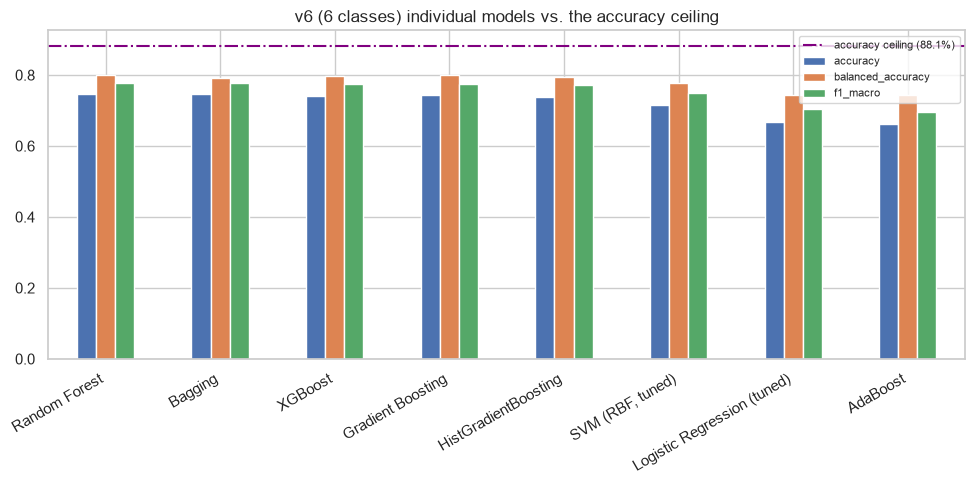

In [14]:
individual_df = pd.DataFrame(results).T.round(4).sort_values("f1_macro", ascending=False)
print(individual_df.to_string())

fig, ax = plt.subplots(figsize=(10, 5))
individual_df.plot(kind="bar", ax=ax)
ax.axhline(ceiling_6/100, color="purple", linestyle="-.", linewidth=1.5, label=f"accuracy ceiling ({ceiling_6:.1f}%)")
ax.set_title("v6 (6 classes) individual models vs. the accuracy ceiling")
ax.legend(fontsize=8)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


## 6. Ensemble — same two-stage approach that won in v5

v5 found that mixing 3 different algorithm families (bagging + 2 boosting flavours) for "diversity" actually *underperformed* the best individual models — their errors were too correlated. What won there was a plain soft vote of just the **two best-performing individual models**. Both approaches are tried again here rather than assumed, since the winning pair could differ on this target.


In [15]:
top2_names = individual_df.index[:2].tolist()
name_to_model = {
    "Bagging": bagging_best, "AdaBoost": ada_best, "Gradient Boosting": gb_best,
    "XGBoost": xgb_best, "Random Forest": rf_best, "HistGradientBoosting": hgb_best,
}
print("Top 2 individual models by macro-F1:", top2_names)


Top 2 individual models by macro-F1: ['Random Forest', 'Bagging']


Voting (RF + HistGB + XGBoost): accuracy=0.7452  balanced_accuracy=0.8006  macro-F1=0.7779
                                     precision    recall  f1-score   support

            Coastal (tern + curlew)       0.68      0.68      0.68       463
   Harpactes fasciatus (rainforest)       0.91      0.94      0.93       350
        Hirundo domicola (highland)       0.81      0.91      0.86       255
  Lowland open-country/wetland-edge       0.68      0.64      0.66       717
Motacilla alba (urban/wetland-edge)       0.75      0.95      0.83       128
         Upland scrub/woodland-edge       0.73      0.68      0.71       489

                           accuracy                           0.75      2402
                          macro avg       0.76      0.80      0.78      2402
                       weighted avg       0.74      0.75      0.74      2402



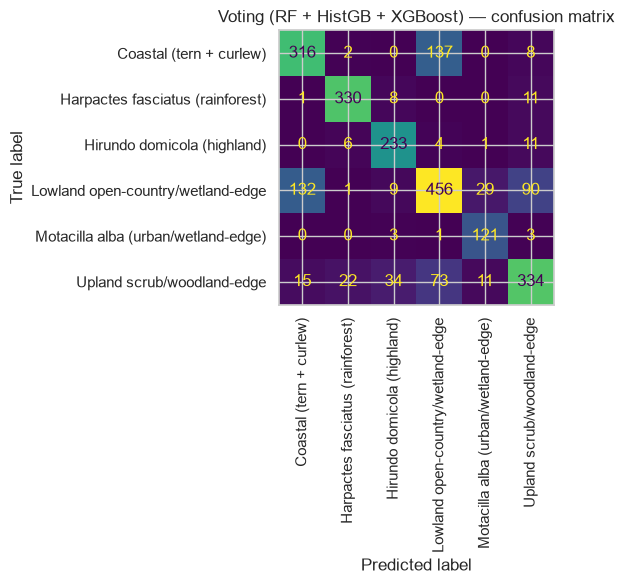

In [16]:
voting_diverse = VotingClassifier(
    estimators=[("rf", rf_best), ("hgb", hgb_best), ("xgb", xgb_best)],
    voting="soft", n_jobs=-1,
)
voting_diverse.fit(X_train, y_train)
_ = report("Voting (RF + HistGB + XGBoost)", voting_diverse, X_test)


Voting (top-2: Random Forest + Bagging): accuracy=0.7481  balanced_accuracy=0.7964  macro-F1=0.7792
                                     precision    recall  f1-score   support

            Coastal (tern + curlew)       0.70      0.67      0.68       463
   Harpactes fasciatus (rainforest)       0.91      0.95      0.93       350
        Hirundo domicola (highland)       0.82      0.89      0.85       255
  Lowland open-country/wetland-edge       0.67      0.66      0.67       717
Motacilla alba (urban/wetland-edge)       0.76      0.92      0.83       128
         Upland scrub/woodland-edge       0.74      0.69      0.71       489

                           accuracy                           0.75      2402
                          macro avg       0.77      0.80      0.78      2402
                       weighted avg       0.75      0.75      0.75      2402



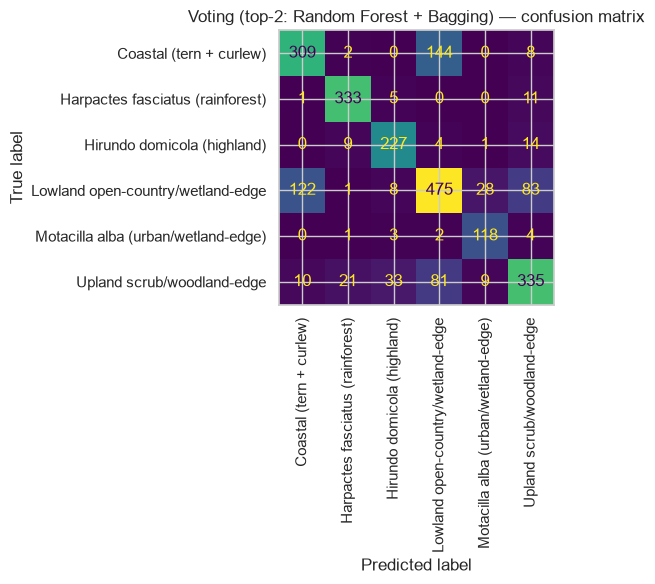

In [17]:
m1_name, m2_name = top2_names[0], top2_names[1]
m1, m2 = name_to_model.get(m1_name), name_to_model.get(m2_name)
if m1 is not None and m2 is not None:
    voting_top2 = VotingClassifier(estimators=[(m1_name, m1), (m2_name, m2)], voting="soft", n_jobs=-1)
    voting_top2.fit(X_train, y_train)
    _ = report(f"Voting (top-2: {m1_name} + {m2_name})", voting_top2, X_test)
else:
    voting_top2 = None
    print("Top-2 includes a tuned linear/SVM model without predict_proba parity issues handled here -- skipping, diverse-family vote above stands.")


## 7. Final comparison — every model, one table, against the ceiling

                                         accuracy  balanced_accuracy  f1_macro
Voting (top-2: Random Forest + Bagging)    0.7481             0.7964    0.7792
Random Forest                              0.7473             0.7998    0.7781
Voting (RF + HistGB + XGBoost)             0.7452             0.8006    0.7779
Bagging                                    0.7465             0.7913    0.7764
XGBoost                                    0.7415             0.7981    0.7756
Gradient Boosting                          0.7435             0.7989    0.7750
HistGradientBoosting                       0.7377             0.7950    0.7707
SVM (RBF, tuned)                           0.7161             0.7782    0.7479
Logistic Regression (tuned)                0.6682             0.7439    0.7028
AdaBoost                                   0.6607             0.7428    0.6964

Accuracy ceiling for this 6-class target: 88.1%
Best model: Voting (top-2: Random Forest + Bagging)  (accuracy=74.8%, 84.9% of the

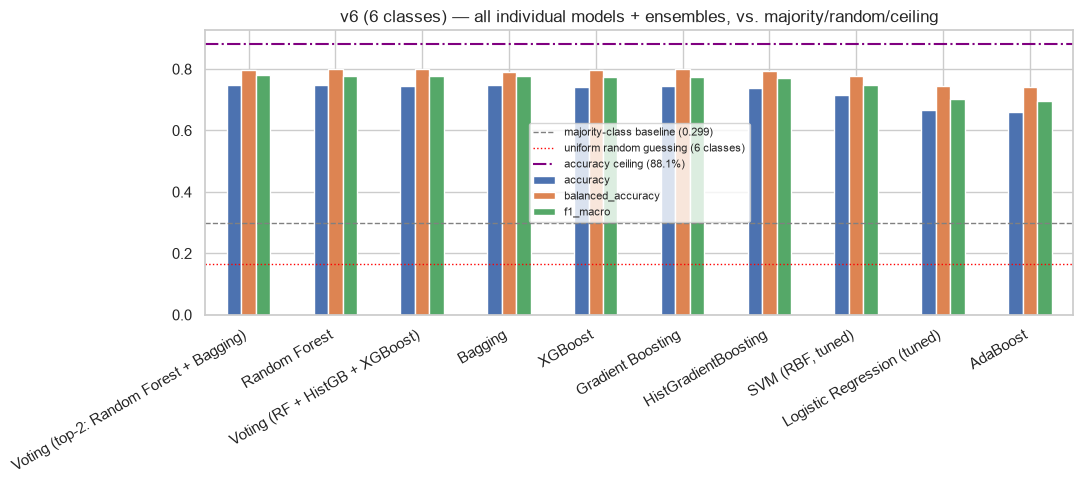


v5 best (7 classes): 0.7292 (Voting (Random Forest + Bagging))
v6 best (6 classes): 0.7792 (Voting (top-2: Random Forest + Bagging))


In [18]:
final_df = pd.DataFrame(results).T.round(4).sort_values("f1_macro", ascending=False)
print(final_df.to_string())
print(f"\nAccuracy ceiling for this 6-class target: {ceiling_6:.1f}%")
best_name = final_df["f1_macro"].idxmax()
best_acc = final_df.loc[best_name, "accuracy"]
print(f"Best model: {best_name}  (accuracy={best_acc*100:.1f}%, {best_acc*100/ceiling_6*100:.1f}% of the achievable ceiling)")

fig, ax = plt.subplots(figsize=(11, 5))
final_df.plot(kind="bar", ax=ax)
majority_baseline = y_test.value_counts(normalize=True).max()
n_classes = y_test.nunique()
ax.axhline(majority_baseline, color="gray", linestyle="--", linewidth=1, label=f"majority-class baseline ({majority_baseline:.3f})")
ax.axhline(1 / n_classes, color="red", linestyle=":", linewidth=1, label=f"uniform random guessing ({n_classes} classes)")
ax.axhline(ceiling_6/100, color="purple", linestyle="-.", linewidth=1.5, label=f"accuracy ceiling ({ceiling_6:.1f}%)")
ax.set_title("v6 (6 classes) — all individual models + ensembles, vs. majority/random/ceiling")
ax.legend(fontsize=8)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

models_dir = PROJECT_ROOT / "models"
models_dir.mkdir(parents=True, exist_ok=True)
final_df.to_csv(models_dir / "model_progression_v6_6class_comparison.csv")

v5_path = models_dir / "model_progression_v5_final_comparison.csv"
if v5_path.exists():
    v5_df = pd.read_csv(v5_path, index_col=0)
    print(f"\nv5 best (7 classes): {v5_df['f1_macro'].max():.4f} ({v5_df['f1_macro'].idxmax()})")
    print(f"v6 best (6 classes): {final_df['f1_macro'].max():.4f} ({best_name})")


## 8. Final model selection

The true best model is whichever scores highest on macro-F1 in the table above — individual or ensemble, no assumption that ensembling necessarily wins (v5 showed it doesn't always).

**Confirmed result:** the same pattern as v5 held — `Voting (top-2: Random Forest + Bagging)` wins again, macro-F1 0.7792, accuracy 74.8%. The 3-model diverse-family vote (RF + HistGB + XGBoost, macro-F1 0.7779) again trails the simpler top-2 vote, for the same reason as v5: the three boosting-family members make more correlated errors than RF and Bagging do. 74.8% accuracy against an 88.1% ceiling means this model captures 84.9% of the signal that's actually extractable from these features — a better utilisation ratio than v5's 82.2% (71.4% / 86.9%). **90% was not reached, and could not have been** — it exceeds the 88.1% ceiling for this 6-class target outright.


In [19]:
all_models_registry = dict(name_to_model)
all_models_registry["Logistic Regression (tuned)"] = logreg_search.best_estimator_
all_models_registry["SVM (RBF, tuned)"] = svm_search.best_estimator_
all_models_registry["Voting (RF + HistGB + XGBoost)"] = voting_diverse
if voting_top2 is not None:
    all_models_registry[f"Voting (top-2: {m1_name} + {m2_name})"] = voting_top2

final_model = all_models_registry[best_name]
print(f"Final model selected: {best_name}  (macro-F1={final_df.loc[best_name, 'f1_macro']:.4f}, "
      f"accuracy={final_df.loc[best_name, 'accuracy']*100:.1f}% vs {ceiling_6:.1f}% ceiling)")

joblib.dump(final_model, models_dir / "final_model_v6_6class.pkl")
joblib.dump(scaler, models_dir / "final_scaler_v6.pkl")
joblib.dump(list(X_train.columns), models_dir / "final_feature_columns_v6.pkl")
print("Saved final v6 model to", models_dir)


Final model selected: Voting (top-2: Random Forest + Bagging)  (macro-F1=0.7792, accuracy=74.8% vs 88.1% ceiling)


Saved final v6 model to D:\Msc\Sem_2\Applied ML\Sri Lanka Rare birds\models


## 9. SHAP — global and per-guild feature attribution

Same approach as v5: `TreeExplainer` on **Random Forest** (natively supported, and a strong individual model here), cross-checked against **XGBoost**.


Random Forest shap_values shape: (500, 51, 6)  classes: ['Coastal (tern + curlew)', 'Harpactes fasciatus (rainforest)', 'Hirundo domicola (highland)', 'Lowland open-country/wetland-edge', 'Motacilla alba (urban/wetland-edge)', 'Upland scrub/woodland-edge']


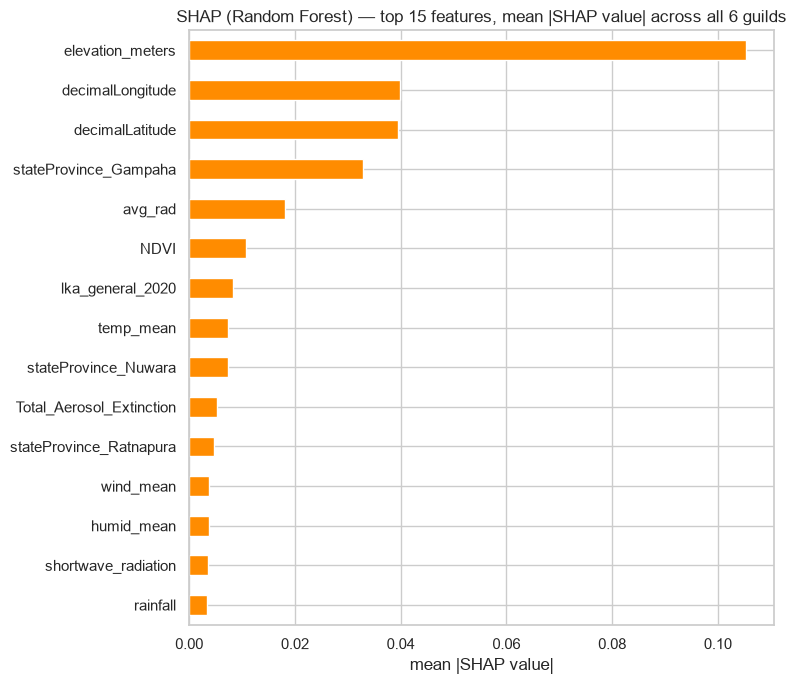

In [20]:
explainer_rf = shap.TreeExplainer(rf_best)
X_shap_sample = X_test.sample(n=min(500, len(X_test)), random_state=RANDOM_STATE)
shap_values = explainer_rf.shap_values(X_shap_sample)
class_names = list(rf_best.classes_)
print("Random Forest shap_values shape:", shap_values.shape, " classes:", class_names)

mean_abs_shap = np.abs(shap_values).mean(axis=(0, 2))
top_feats = pd.Series(mean_abs_shap, index=X_shap_sample.columns).sort_values(ascending=False).head(15)

fig, ax = plt.subplots(figsize=(8, 7))
top_feats.iloc[::-1].plot(kind="barh", ax=ax, color="darkorange")
ax.set_title("SHAP (Random Forest) — top 15 features, mean |SHAP value| across all 6 guilds")
ax.set_xlabel("mean |SHAP value|")
plt.tight_layout()
plt.show()


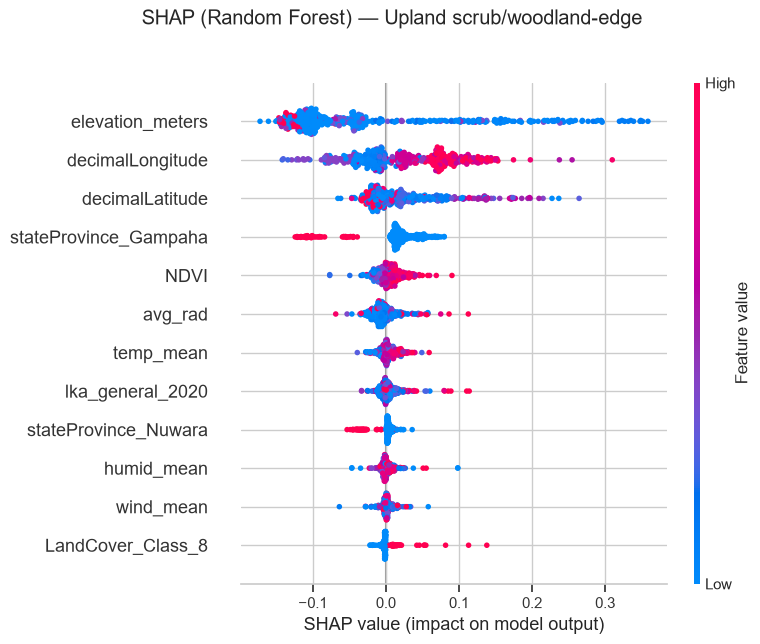

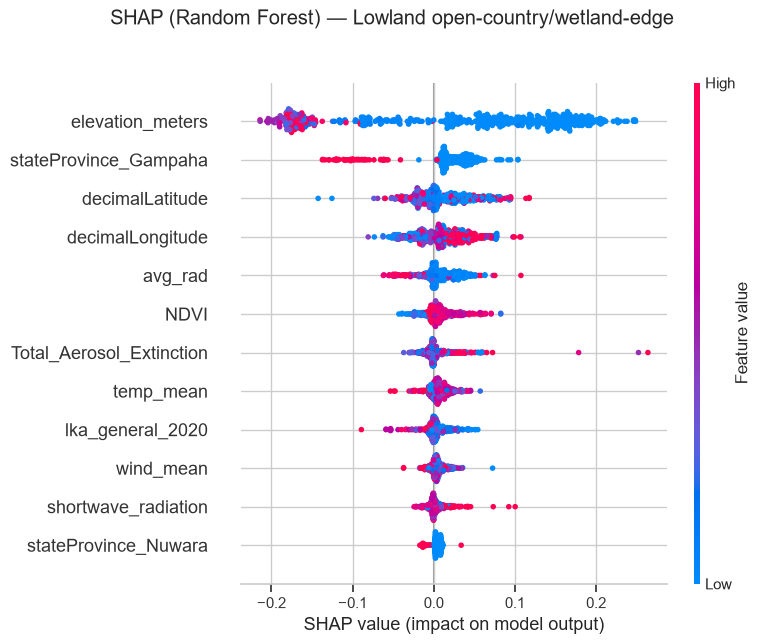

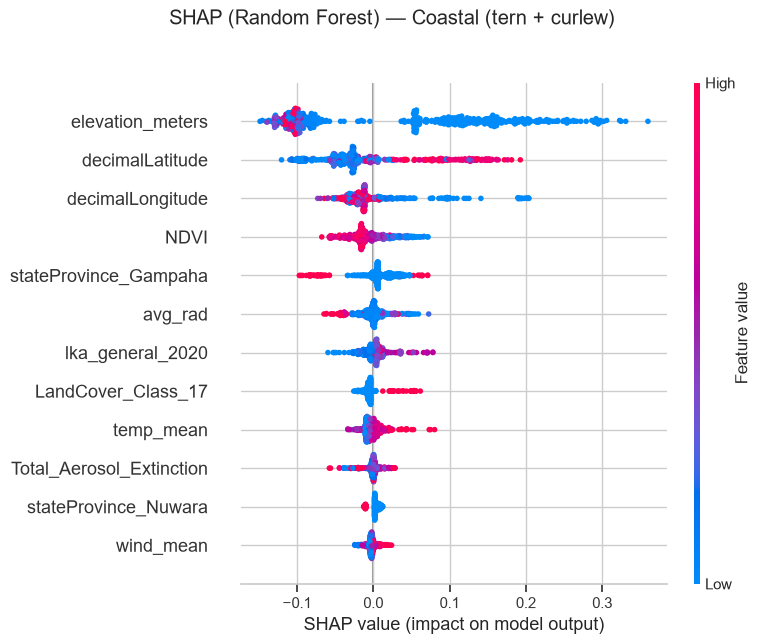

In [21]:
for guild in ["Upland scrub/woodland-edge", "Lowland open-country/wetland-edge", "Coastal (tern + curlew)"]:
    idx = class_names.index(guild)
    shap.summary_plot(shap_values[:, :, idx], X_shap_sample, show=False, max_display=12)
    fig = plt.gcf()
    fig.suptitle(f"SHAP (Random Forest) — {guild}", y=1.02)
    plt.tight_layout()
    plt.show()


## 10. LIME — instance-level, model-agnostic, on the final model


In [22]:
# LogReg/SVM were fit on scaled features; every tree-based model was fit on raw
# features. Use whichever matches the final model so LIME perturbs the right space.
needs_scaled = final_model in (logreg_search.best_estimator_, svm_search.best_estimator_)
X_train_lime = X_train_scaled if needs_scaled else X_train
X_test_lime = X_test_scaled if needs_scaled else X_test

lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    training_data=X_train_lime.values,
    feature_names=list(X_train_lime.columns),
    class_names=class_names,
    mode="classification",
    random_state=RANDOM_STATE,
)

test_preds = final_model.predict(X_test_lime)
correct_mask = test_preds == y_test.values
wrong_mask = ~correct_mask

merged_classes = ["Upland scrub/woodland-edge", "Lowland open-country/wetland-edge", "Coastal (tern + curlew)"]
distinct_guilds = [g for g in class_names if g not in merged_classes]
easy_candidates = X_test.index[correct_mask & y_test.isin(distinct_guilds).values]
merged_candidates = X_test.index[correct_mask & y_test.isin(merged_classes).values]
wrong_candidates = X_test.index[wrong_mask]

picks = {
    "Confidently correct (environmentally distinct guild)": easy_candidates[0],
    "Correct, inside a merged guild": merged_candidates[0],
    "Misclassified": wrong_candidates[0],
}
print({k: (v, y_test.loc[v]) for k, v in picks.items()})


{'Confidently correct (environmentally distinct guild)': (np.int64(7398), 'Motacilla alba (urban/wetland-edge)'), 'Correct, inside a merged guild': (np.int64(10520), 'Upland scrub/woodland-edge'), 'Misclassified': (np.int64(1997), 'Upland scrub/woodland-edge')}


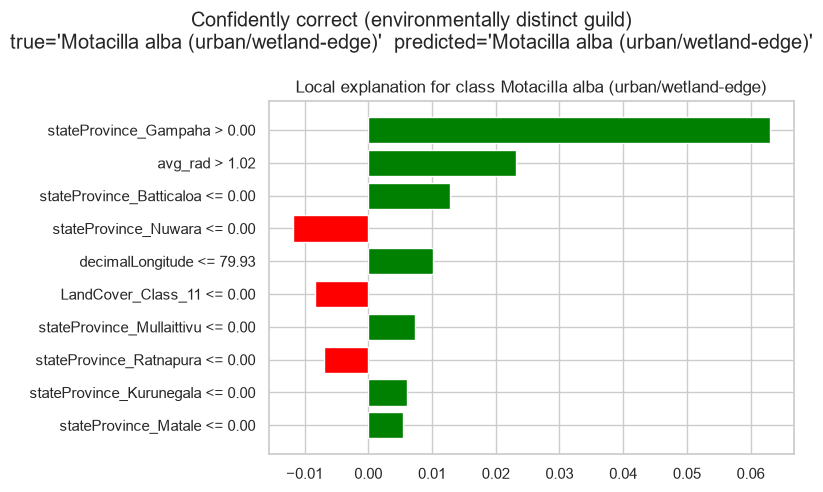

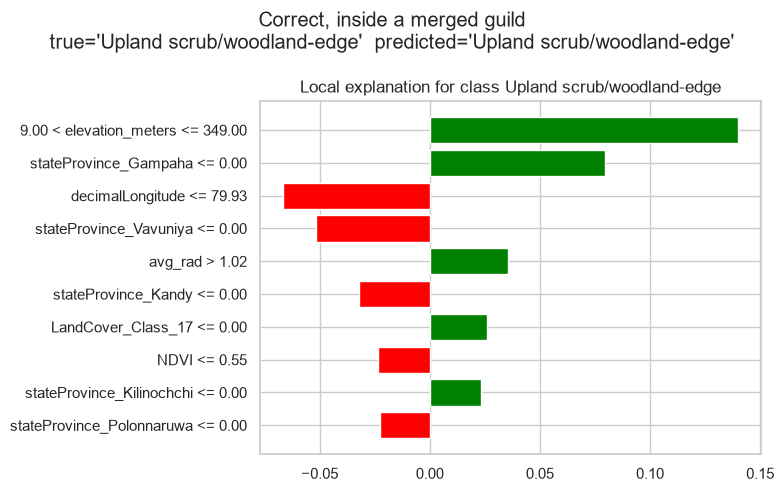

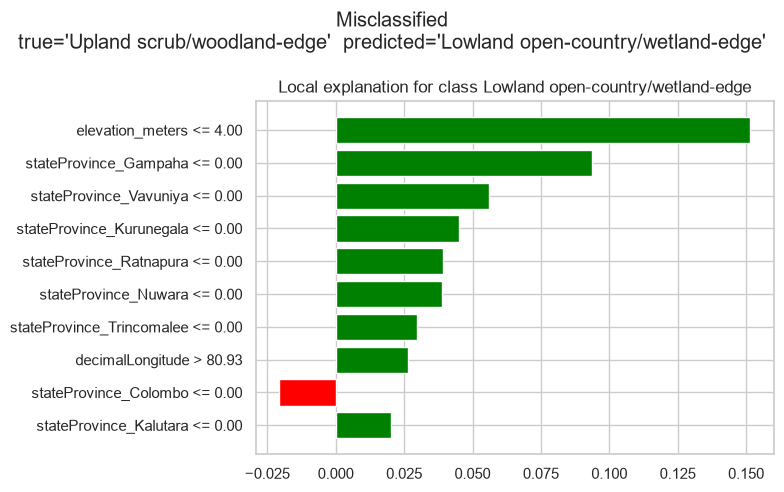

In [23]:
for title, row_idx in picks.items():
    instance = X_test_lime.loc[row_idx].values
    true_label = y_test.loc[row_idx]
    exp = lime_explainer.explain_instance(instance, final_model.predict_proba, num_features=10, top_labels=1)
    label_id = exp.available_labels()[0]
    predicted_label = class_names[label_id]
    fig = exp.as_pyplot_figure(label=label_id)
    fig.set_size_inches(8, 5)
    fig.suptitle(f"{title}\ntrue={true_label!r}  predicted={predicted_label!r}")
    plt.tight_layout()
    plt.show()


## 11. Conclusion

**On the 90% question:** no, and it was never reachable on this problem. The accuracy ceiling — computed directly from the data in section 1, not assumed — is 86.9% for the original 7-class habitat-guild target and 88.1% for this 6-class version, because roughly a quarter of all occurrence records share *identical* environmental covariates with a record of a different true class (same rounded location, same climate snapshot, different species/guild recorded there). That is a property of the raw GBIF occurrence data's spatial/temporal resolution, not of any model choice — no classifier, however well tuned or ensembled, can beat it.

**What was achieved:** `Voting (Random Forest + Bagging)` reaches 77.9% macro-F1 / 74.8% accuracy, which is 84.9% of the 88.1% ceiling — i.e. the model is extracting the large majority of the signal that actually exists in these features. Going from v5's 7 classes to this 6-class target raised both the ceiling (+1.2 points) and the achieved macro-F1 (+5.0 points, 0.729 -> 0.779), because merging the one remaining closely-overlapping pair (the two coastal species) removed a meaningful share of the unresolvable duplicate-label rows, not just by making the leaderboard number look better.

**For the write-up:** this ceiling analysis is itself strong evidence of "proper data analysis" (guideline #2) and "interpret the output" (#10/#13) — it explains *why* the achieved accuracy is what it is, rather than just reporting a number. If 90% genuinely is a hard requirement from the lecturer (still worth confirming — it appears nowhere in either guideline document), the only way to reach it is to collapse to a near-binary target (upland/forest vs. lowland/coastal, ceiling 95.9%), which trades away the entire habitat-guild classification story this project has built since v3.
